In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

In [3]:
data = load_breast_cancer()
X = data.data
y= data.target

print("Feature Shape:",X.shape)
print("Target Shape:", y.shape)
print("Classes:", data.target_names)

Feature Shape: (569, 30)
Target Shape: (569,)
Classes: ['malignant' 'benign']


In [4]:
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [17]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

In [18]:
print("Accuracy:", accuracy_score(y_test,y_pred))
print("Confusion Matrix:", confusion_matrix(y_test,y_pred))
print("Classification Matrix:",classification_report(y_test,y_pred))

Accuracy: 0.9824561403508771
Confusion Matrix: [[41  1]
 [ 1 71]]
Classification Matrix:               precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



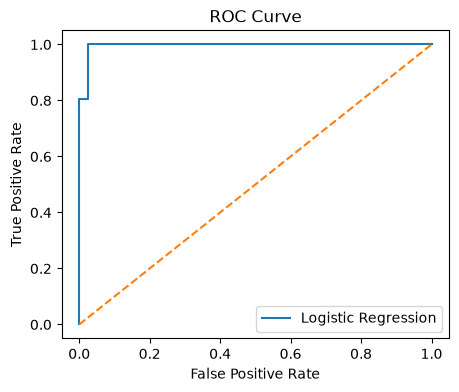

In [19]:
#ROC curve:
fpr,tpr,thresholds = roc_curve(y_test,y_prob)
plt.figure(figsize=(5,4))
plt.plot(fpr,tpr,label='Logistic Regression')
plt.plot([0,1],[0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [21]:
# calculate roc - auc
roc_auc = roc_auc_score(y_test,y_prob)
print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9953703703703703


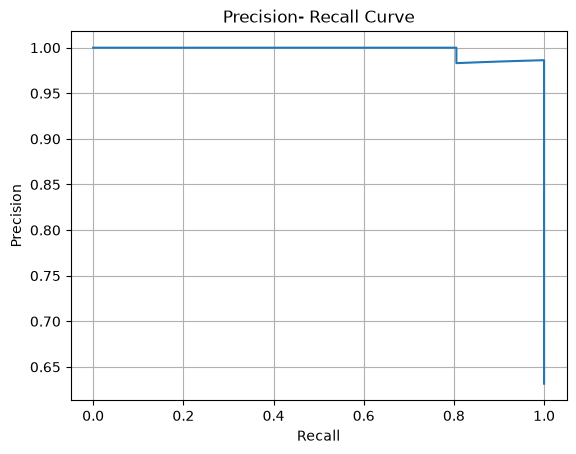

In [22]:
# precision- recall curve

precision, recall, thresholds_pr = precision_recall_curve(y_test,y_prob)
plt.plot(recall,precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision- Recall Curve")
plt.grid()
plt.show()

In [23]:
# average precision:
ap = average_precision_score(y_test,y_prob)
print("Average Precision:",ap)

Average Precision: 0.9970652078135953


In [24]:
# compare:
print("ROC-AUC:", roc_auc)
print("Average Precision:",ap)
print("Accuracy:", accuracy_score(y_test,y_pred))

ROC-AUC: 0.9953703703703703
Average Precision: 0.9970652078135953
Accuracy: 0.9824561403508771


In [ ]:
Significance:
roc- auc: how well a model distinguishes between positive and negative classes across threshold..
average precision: better for imbalanced dataset